# SQL Query Fundamentals (SELECT, WHERE, GROUP BY)

**SQL** (Structured Query Language) asks questions of a relational database. You describe **what** you want; the database decides **how** to get it. This lesson covers the clauses that answer most business questions.

**After this lesson you can:**

1. Select and compute columns with `SELECT`, aliases and expressions.
2. Filter rows with `WHERE`: comparisons, `IN`, `BETWEEN`, `LIKE`, `NULL` handling.
3. Sort and limit results.
4. Aggregate with `GROUP BY` and filter groups with `HAVING`.
5. Explain the logical order in which SQL evaluates a query.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. SELECT: Columns and Expressions

```sql
SELECT column, expression AS alias
FROM table;
```

Avoid `SELECT *` in production code: it reads columns you do not need and breaks when the table changes.

In [2]:
q("""
SELECT name AS track,
       round(milliseconds / 60000.0, 2) AS minutes,
       round(bytes / 1024.0 / 1024.0, 1) AS megabytes,
       unit_price
FROM track
LIMIT 5
""")

,track,minutes,megabytes,unit_price
0,For Those About To Rock (We Salute You),5.73,10.7,0.99
1,Balls to the Wall,5.71,5.3,0.99
2,Fast As a Shark,3.84,3.8,0.99
3,Restless and Wild,4.20,4.1,0.99
4,Princess of the Dawn,6.26,6.0,0.99


## 2. WHERE: Filter Rows

| Operator | Example |
| :--- | :--- |
| `=`, `<>`, `<`, `>=` | `unit_price > 0.99` |
| `AND`, `OR`, `NOT` | `country = 'USA' AND city <> 'Boston'` |
| `IN (...)` | `country IN ('Brazil', 'Portugal')` |
| `BETWEEN a AND b` | `invoice_date BETWEEN '2024-01-01' AND '2024-12-31'` (inclusive) |
| `LIKE` / `ILIKE` | `name ILIKE '%love%'` (`ILIKE` ignores case) |
| `IS NULL` / `IS NOT NULL` | `company IS NULL` |

`NULL` means "unknown". Any comparison with `NULL` (also `NULL = NULL`) is unknown, not true. Use `IS NULL`.

In [3]:
print(q("SELECT count(*) AS love_songs FROM track WHERE name ILIKE '%love%'"))
print(q("SELECT count(*) AS with_company FROM customer WHERE company IS NOT NULL"))
print(q("SELECT count(*) AS wrong_null_check FROM customer WHERE company = NULL"), "  <- always 0: use IS NULL")
q("""
SELECT first_name, last_name, city, country
FROM customer
WHERE country IN ('Brazil', 'Portugal') AND city <> 'São Paulo'
ORDER BY country, last_name
""")

   love_songs
0         114


   with_company
0            10


   wrong_null_check
0                 0   <- always 0: use IS NULL


,first_name,last_name,city,country
0,Roberto,Almeida,Rio de Janeiro,Brazil
1,Luís,Gonçalves,São José dos Campos,Brazil
2,Fernanda,Ramos,Brasília,Brazil
3,João,Fernandes,Lisbon,Portugal
4,Madalena,Sampaio,Porto,Portugal


## 3. ORDER BY and LIMIT

`ORDER BY col DESC` sorts in descending order; `LIMIT n` returns the first *n* rows. Without `ORDER BY`, the order of rows is **not defined**: never rely on it.

In [4]:
q("""
SELECT t.name AS track, round(t.milliseconds / 60000.0, 1) AS minutes, g.name AS genre
FROM track t JOIN genre g ON g.genre_id = t.genre_id
ORDER BY t.milliseconds DESC
LIMIT 5
""")

,track,minutes,genre
0,Occupation / Precipice,88.1,TV Shows
1,Through a Looking Glass,84.8,Drama
2,"Greetings from Earth, Pt. 1",49.3,Sci Fi & Fantasy
3,The Man With Nine Lives,49.3,Sci Fi & Fantasy
4,"Battlestar Galactica, Pt. 2",49.3,Sci Fi & Fantasy


## 4. GROUP BY and HAVING

`GROUP BY` puts rows with the same values into groups; **aggregate functions** compute one value per group: `count`, `sum`, `avg`, `min`, `max`. `HAVING` filters **groups** (after aggregation); `WHERE` filters **rows** (before aggregation).

In [5]:
by_country = q("""
SELECT billing_country AS country,
       count(*)                AS invoices,
       count(DISTINCT customer_id) AS customers,
       sum(total)              AS revenue,
       round(avg(total), 2)    AS avg_invoice
FROM invoice
GROUP BY billing_country
HAVING sum(total) > 75
ORDER BY revenue DESC
""")
by_country

,country,invoices,customers,revenue,avg_invoice
0,USA,91,13,523.06,5.75
1,Canada,56,8,303.96,5.43
2,France,35,5,195.10,5.57
3,Brazil,35,5,190.10,5.43
4,Germany,28,4,156.48,5.59
5,United Kingdom,21,3,112.86,5.37
6,Czech Republic,14,2,90.24,6.45
7,Portugal,14,2,77.24,5.52
8,India,13,2,75.26,5.79


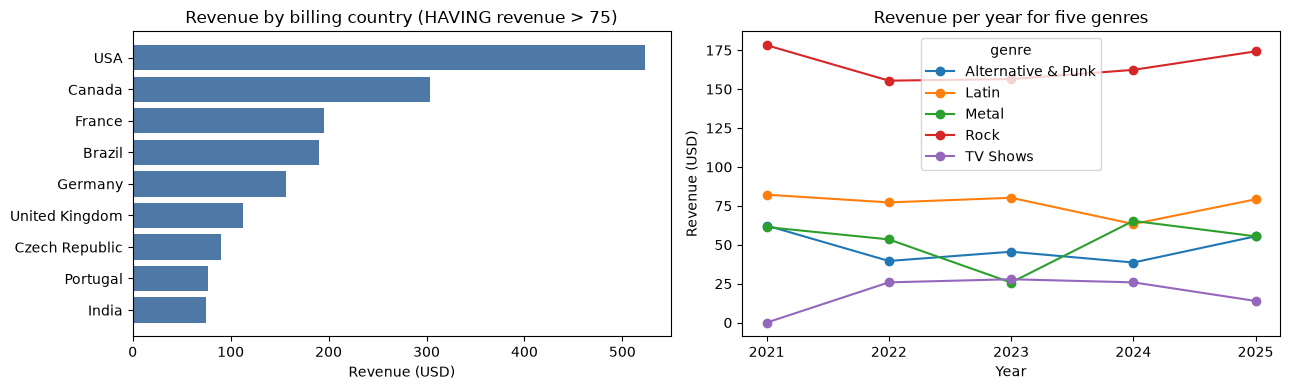

In [6]:
yearly = q("""
SELECT extract(year FROM invoice_date)::int AS year, g.name AS genre, sum(il.unit_price * il.quantity) AS revenue
FROM invoice_line il
JOIN invoice i ON i.invoice_id = il.invoice_id
JOIN track t ON t.track_id = il.track_id
JOIN genre g ON g.genre_id = t.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal', 'Alternative & Punk', 'TV Shows')
GROUP BY 1, 2
ORDER BY 1, 2
""")
pivot = yearly.pivot(index="year", columns="genre", values="revenue").fillna(0).astype(float)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.barh(by_country["country"][::-1], by_country["revenue"][::-1].astype(float), color="#4E79A7")
ax1.set(title="Revenue by billing country (HAVING revenue > 75)", xlabel="Revenue (USD)")
pivot.plot(ax=ax2, marker="o")
ax2.set(title="Revenue per year for five genres", xlabel="Year", ylabel="Revenue (USD)")
ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

## 5. The Logical Order of a Query

SQL is written in one order but evaluated in another. This explains why you cannot use a `SELECT` alias in `WHERE`, but you can use it in `ORDER BY`:

| Written | Evaluated |
| :-: | :-: |
| 1 `SELECT` | 5 |
| 2 `FROM` / `JOIN` | 1 |
| 3 `WHERE` | 2 |
| 4 `GROUP BY` | 3 |
| 5 `HAVING` | 4 |
| 6 `ORDER BY` | 6 |
| 7 `LIMIT` | 7 |

In [7]:
try:
    q("SELECT total * 0.9 AS discounted FROM invoice WHERE discounted > 20")
except Exception as err:
    print("alias in WHERE ->", str(err.__cause__.orig).splitlines()[0])
q("SELECT invoice_id, total * 0.9 AS discounted FROM invoice ORDER BY discounted DESC LIMIT 3")

alias in WHERE -> column "discounted" does not exist


,invoice_id,discounted
0,404,23.274
1,299,21.474
2,194,19.674


*Insight: Translate a business question into SQL clause by clause: which table (`FROM`), which rows (`WHERE`), which groups (`GROUP BY`), which numbers (aggregates), which groups to keep (`HAVING`), in which order (`ORDER BY`). Always check `NULL` handling and the grain (one row = what?) of the result.*

## Real-World Use Case or Analogy

A SQL query is like a **request to a warehouse clerk**: "From the invoice shelf (`FROM`), take only last year's invoices (`WHERE`), sort them into piles by country (`GROUP BY`), give me the total of each pile (`SUM`), but only piles above 75 dollars (`HAVING`), largest first (`ORDER BY`)." You do not tell the clerk how to walk through the warehouse; the database's query planner does that (Lesson 10).

Analysts write queries like these every day to build reports and dashboards (M09); data scientists use them to build training datasets (M10, M16).